# Previsão de Reajustes Contratuais — Serviços Profissionais
**Modelos e KPIs.** Base sintética de 1.000 eventos (1 linha = 1 evento de reajuste), IPCA 12m oficial (IBGE).

**Desenho de validação (backtest):** treino com data-base 2022–2024, teste em **2025** (ano fechado: real × previsto).
Eventos de **2026** (jan–out) são usados como **simulação de uso**, com o modelo retreinado em 2022–2025.

> A base sintética demonstra o funcionamento da metodologia, mas não comprova capacidade preditiva sobre contratos reais.
> Os KPIs a seguir são **demonstrativos**, não ganhos obtidos pela empresa.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import mean_absolute_error, accuracy_score, confusion_matrix

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 160)
SEED = 42

from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, REP = ROOT / "data", ROOT / "reports"
(REP / "figures").mkdir(parents=True, exist_ok=True)

base = pd.read_csv(DATA / "base_reajustes_sinteticos.csv", sep=";", decimal=",",
                   parse_dates=["data_inicio_contrato", "data_base_reajuste"])
base["ano"] = base["data_base_reajuste"].dt.year
print(base.shape)
base.groupby("ano").size().rename("eventos").to_frame().T

(1000, 26)


ano,2022,2023,2024,2025,2026
eventos,157,189,205,242,207


import warnings; warnings.filterwarnings("ignore")
## 1. Preparação
- **Exclusão:** eventos com `escopo_alterado = 1` saem do treino e do teste (o modelo confundiria aumento de escopo com reajuste de preço).
- **Histórico sem vazamento:** as variáveis de histórico usam apenas eventos com data-base **anterior** ao evento.
  - `hist_forn_premio_pedido`: quanto o fornecedor costuma pedir acima do IPCA (média dos reajustes anteriores);
  - `hist_forn_concessao`: quanto o fornecedor costuma ceder na negociação (p.p.);
  - `premio_anterior_contrato`: prêmio pedido no ciclo anterior do mesmo contrato.
  Informações de **reajustes passados** já são conhecidas antes da nova solicitação — não há vazamento.
- `ipca_excedente_6` = max(0, IPCA − 6): captura o regime de inflação alta de 2022, em que Compras obteve reajustes abaixo do IPCA.
- **Modelo A (orçamento)** não usa nenhuma variável posterior à solicitação do fornecedor.

In [2]:
df = base[base["escopo_alterado"] == 0].sort_values(["data_base_reajuste", "id_evento"]).copy()

# histórico do fornecedor (só datas-base estritamente anteriores):
#   prêmio médio que costuma PEDIR acima do IPCA e quanto costuma CEDER na negociação
def hist_forn(col):
    agg = (df.groupby(["fornecedor_id", "data_base_reajuste"])[col].agg(["sum", "count"])
             .groupby(level=0).cumsum().groupby(level=0).shift(1))
    return (agg["sum"] / agg["count"]).rename(f"hist_forn_{col}")


for c in ["delta_solicitado_ipca_pp", "economia_negociacao_pp"]:
    df = df.merge(hist_forn(c).reset_index(), on=["fornecedor_id", "data_base_reajuste"], how="left")
df = df.rename(columns={"hist_forn_delta_solicitado_ipca_pp": "hist_forn_premio_pedido",
                        "hist_forn_economia_negociacao_pp": "hist_forn_concessao"})

# reajuste anterior do mesmo contrato (prêmio pedido no ciclo anterior)
df = df.sort_values(["id_contrato", "data_base_reajuste"])
df["premio_anterior_contrato"] = df.groupby("id_contrato")["delta_solicitado_ipca_pp"].shift(1)
df["sem_historico_contrato"] = df["premio_anterior_contrato"].isna().astype(int)
df["sem_historico_forn"] = df["hist_forn_premio_pedido"].isna().astype(int)
HIST = ["hist_forn_premio_pedido", "hist_forn_concessao", "premio_anterior_contrato"]
df[HIST] = df[HIST].fillna(0)
df["log_valor"] = np.log(df["valor_anual_antes"])
df["ipca_excedente_6"] = (df["ipca_12m_pct"] - 6).clip(lower=0)   # regime de inflação alta
df = df.sort_values(["data_base_reajuste", "id_evento"]).reset_index(drop=True)

NUM_A = ["ipca_12m_pct", "ipca_excedente_6", "log_valor", "meses_desde_ultimo_reajuste", "numero_reajuste_contrato",
         "hist_forn_premio_pedido", "hist_forn_concessao", "sem_historico_forn",
         "premio_anterior_contrato", "sem_historico_contrato", "renovacao_concomitante"]
CAT = ["categoria", "modelo_remuneracao", "indice_contratual"]
NUM_B = NUM_A + ["reajuste_solicitado_pct"]


def matriz(d, num):
    X = pd.get_dummies(d[num + CAT], columns=CAT, drop_first=True, dtype=float)
    return X


XA_all, XB_all = matriz(df, NUM_A), matriz(df, NUM_B)
y_all = df["reajuste_aprovado_pct"]

treino = df["ano"] <= 2024
teste = df["ano"] == 2025
sim = df["ano"] == 2026
print(f"Treino 2022–2024: {treino.sum()} | Teste 2025: {teste.sum()} | Simulação 2026: {sim.sum()} "
      f"| excluídos por escopo: {(base['escopo_alterado'] == 1).sum()}")

Treino 2022–2024: 508 | Teste 2025: 217 | Simulação 2026: 196 | excluídos por escopo: 79


## 2. Modelos
- **Modelo 0 — Baseline:** reajuste esperado = IPCA 12m.
- **Modelo 1A — Regressão Linear (orçamento):** antes da solicitação.
- **Modelo 1B — Regressão Linear (negociação):** acrescenta `reajuste_solicitado_pct`.
- **Faixa provável:** previsão + quantis 10% e 90% dos resíduos de treino (intervalo empírico de 80%).

In [3]:
def ajustar_regressao(X, y, idx_tr):
    m = LinearRegression().fit(X[idx_tr], y[idx_tr])
    res = y[idx_tr] - m.predict(X[idx_tr])
    q_lo, q_hi = np.quantile(res, [0.10, 0.90])
    return m, q_lo, q_hi


mA, loA, hiA = ajustar_regressao(XA_all, y_all, treino)
mB, loB, hiB = ajustar_regressao(XB_all, y_all, treino)

t = df[teste].copy()
t["prev_baseline"] = t["ipca_12m_pct"]
t["prev_A"] = mA.predict(XA_all[teste]).clip(0)
t["prev_B"] = np.minimum(mB.predict(XB_all[teste]).clip(0), t["reajuste_solicitado_pct"].where(t["reajuste_solicitado_pct"] > 0, np.inf))
t["faixa_A_min"], t["faixa_A_max"] = (t["prev_A"] + loA).clip(0), t["prev_A"] + hiA
t["faixa_B_min"], t["faixa_B_max"] = (t["prev_B"] + loB).clip(0), t["prev_B"] + hiB


def kpi_previsao(col, lo=None, hi=None):
    real = t["reajuste_aprovado_pct"]
    out = {"MAE (p.p.)": mean_absolute_error(real, t[col]),
           "Erro mediano (p.p.)": (real - t[col]).abs().median(),
           "% eventos com erro ≤ 0,5 p.p.": ((real - t[col]).abs() <= 0.5).mean() * 100}
    if lo is not None:
        out["Cobertura da faixa (%)"] = ((real >= t[lo]) & (real <= t[hi])).mean() * 100
        out["Largura média da faixa (p.p.)"] = (t[hi] - t[lo]).mean()
    return out


resultado = pd.DataFrame({
    "Modelo 0 – Baseline IPCA": kpi_previsao("prev_baseline"),
    "Modelo 1A – Regressão (orçamento)": kpi_previsao("prev_A", "faixa_A_min", "faixa_A_max"),
    "Modelo 1B – Regressão (negociação)": kpi_previsao("prev_B", "faixa_B_min", "faixa_B_max"),
}).T
ganho = 1 - resultado.loc["Modelo 1A – Regressão (orçamento)", "MAE (p.p.)"] / resultado.loc["Modelo 0 – Baseline IPCA", "MAE (p.p.)"]
print(f"Redução do erro do Modelo 1A vs. baseline: {ganho:.0%}")
resultado

Redução do erro do Modelo 1A vs. baseline: 19%


,MAE (p.p.),Erro mediano (p.p.),"% eventos com erro ≤ 0,5 p.p.",Cobertura da faixa (%),Largura média da faixa (p.p.)
Modelo 0 – Baseline IPCA,0.73,0.54,47.47,NaN,NaN
Modelo 1A – Regressão (orçamento),0.59,0.40,57.14,80.18,1.83
Modelo 1B – Regressão (negociação),0.32,0.15,85.25,89.40,1.39


### Interpretação da Regressão (Modelo 1A)
Coeficiente = variação esperada no % aprovado (p.p.) para +1 unidade da variável (ou vs. categoria de referência).

In [4]:
coef = pd.Series(mA.coef_, index=XA_all.columns).sort_values()
coef.rename("coef_pp").to_frame()

,coef_pp
ipca_excedente_6,-0.45
modelo_remuneracao_Retainer mensal,-0.37
modelo_remuneracao_Preço fixo,-0.19
categoria_Consultoria Tributária/Contábil,-0.17
modelo_remuneracao_Por entrega,-0.16
indice_contratual_INPC,-0.14
indice_contratual_IPCA,-0.11
log_valor,-0.08
categoria_Consultoria de Gestão,-0.06
categoria_Consultoria de Tecnologia,-0.04


## 3. Modelo 2 — Árvore de Decisão
**Alvo:** `faixa_delta_ipca` (Abaixo / Alinhado / Acima / Muito acima do IPCA), com as variáveis do Modelo A.
As faixas absolutas do briefing (0%, até 3%, 3–6%, 6–10%, >10%) concentram quase todo o período pós-2023 em "Moderado",
o que tornaria a árvore trivial; a faixa relativa ao IPCA é o ajuste previsto no briefing após avaliar a distribuição.

In [5]:
ORDEM = ["Abaixo do IPCA", "Alinhado ao IPCA", "Acima do IPCA", "Muito acima do IPCA"]
print("Distribuição absoluta (briefing) no teste 2025:")
print(df.loc[teste, "faixa_reajuste_aprovado"].value_counts(normalize=True).mul(100).round(1).to_string())

arv = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=SEED)
arv.fit(XA_all[treino], df.loc[treino, "faixa_delta_ipca"])
t["prev_faixa"] = arv.predict(XA_all[teste])
acc = accuracy_score(t["faixa_delta_ipca"], t["prev_faixa"])
maj = df.loc[treino, "faixa_delta_ipca"].mode()[0]
acc_maj = (t["faixa_delta_ipca"] == maj).mean()
print(f"\nAcurácia árvore: {acc:.1%} | chute na classe mais frequente ('{maj}'): {acc_maj:.1%}")

mc = pd.DataFrame(confusion_matrix(t["faixa_delta_ipca"], t["prev_faixa"], labels=ORDEM),
                  index=[f"Real: {c}" for c in ORDEM], columns=[f"Prev: {c}" for c in ORDEM])
mc

Distribuição absoluta (briefing) no teste 2025:
faixa_reajuste_aprovado
Moderado       73.70
Alto           24.90
Sem reajuste    1.40

Acurácia árvore: 53.9% | chute na classe mais frequente ('Alinhado ao IPCA'): 47.5%


,Prev: Abaixo do IPCA,Prev: Alinhado ao IPCA,Prev: Acima do IPCA,Prev: Muito acima do IPCA
Real: Abaixo do IPCA,0,14,10,0
Real: Alinhado ao IPCA,0,49,49,5
Real: Acima do IPCA,0,4,54,7
Real: Muito acima do IPCA,0,0,11,14


In [6]:
print(export_text(arv, feature_names=list(XA_all.columns), decimals=2))

|--- ipca_excedente_6 <= 1.95
|   |--- hist_forn_premio_pedido <= 0.55
|   |   |--- sem_historico_forn <= 0.50
|   |   |   |--- class: Alinhado ao IPCA
|   |   |--- sem_historico_forn >  0.50
|   |   |   |--- class: Alinhado ao IPCA
|   |--- hist_forn_premio_pedido >  0.55
|   |   |--- hist_forn_premio_pedido <= 1.62
|   |   |   |--- class: Acima do IPCA
|   |   |--- hist_forn_premio_pedido >  1.62
|   |   |   |--- class: Muito acima do IPCA
|--- ipca_excedente_6 >  1.95
|   |--- modelo_remuneracao_Retainer mensal <= 0.50
|   |   |--- ipca_12m_pct <= 11.51
|   |   |   |--- class: Alinhado ao IPCA
|   |   |--- ipca_12m_pct >  11.51
|   |   |   |--- class: Abaixo do IPCA
|   |--- modelo_remuneracao_Retainer mensal >  0.50
|   |   |--- class: Abaixo do IPCA



## 4. KPIs (teste 2025 — demonstrativos)

In [7]:
t["impacto_real_R$"] = t["valor_anual_antes"] * t["reajuste_aprovado_pct"] / 100
t["impacto_prev_A_R$"] = t["valor_anual_antes"] * t["prev_A"] / 100
t["impacto_prev_base_R$"] = t["valor_anual_antes"] * t["prev_baseline"] / 100
t["economia_R$"] = t["valor_anual_antes"] * t["economia_negociacao_pp"] / 100
t["oportunidade_B"] = (t["reajuste_solicitado_pct"] > t["faixa_A_max"]).astype(int)

real_tot, prevA_tot, base_tot = t["impacto_real_R$"].sum(), t["impacto_prev_A_R$"].sum(), t["impacto_prev_base_R$"].sum()

kpis = pd.DataFrame([
    ["1. Previsibilidade", "Erro médio previsto × realizado (MAE, p.p.)",
     f"{resultado.iloc[1, 0]:.2f} p.p. (baseline IPCA: {resultado.iloc[0, 0]:.2f})"],
    ["2. Orçamento", "Impacto previsto × efetivo (carteira 2025)",
     f"Previsto R$ {prevA_tot/1e6:,.2f} mi × efetivo R$ {real_tot/1e6:,.2f} mi "
     f"(desvio {prevA_tot/real_tot-1:+.1%}; baseline {base_tot/real_tot-1:+.1%}); "
     f"erro médio por contrato R$ {(t['impacto_prev_A_R$']-t['impacto_real_R$']).abs().mean()/1e3:,.1f} mil"],
    ["3. Negociação", "Delta solicitado − aprovado",
     f"{t['economia_negociacao_pp'].mean():.2f} p.p. em média (R$ {t['economia_R$'].sum()/1e6:,.2f} mi evitados); "
     f"nos sinalizados como oportunidade: {t.loc[t.oportunidade_B==1,'economia_negociacao_pp'].mean():.2f} p.p. "
     f"vs. {t.loc[t.oportunidade_B==0,'economia_negociacao_pp'].mean():.2f} p.p. nos demais"],
    ["4. Benchmark", "Delta aprovado vs. IPCA",
     f"{t['delta_aprovado_ipca_pp'].mean():+.2f} p.p. em média; "
     f"{(t['delta_aprovado_ipca_pp']>0.5).mean():.0%} dos eventos acima do IPCA + 0,5 p.p."],
], columns=["KPI", "Métrica", "Resultado 2025 (demonstrativo)"])
with pd.option_context("display.max_colwidth", None):
    display(kpis)

,KPI,Métrica,Resultado 2025 (demonstrativo)
0,1. Previsibilidade,"Erro médio previsto × realizado (MAE, p.p.)",0.59 p.p. (baseline IPCA: 0.73)
1,2. Orçamento,Impacto previsto × efetivo (carteira 2025),Previsto R$ 18.38 mi × efetivo R$ 17.73 mi (desvio +3.7%; baseline -9.0%); erro médio por contrato R$ 8.0 mil
2,3. Negociação,Delta solicitado − aprovado,0.46 p.p. em média (R$ 1.89 mi evitados); nos sinalizados como oportunidade: 0.91 p.p. vs. 0.35 p.p. nos demais
3,4. Benchmark,Delta aprovado vs. IPCA,"+0.40 p.p. em média; 41% dos eventos acima do IPCA + 0,5 p.p."


In [8]:
bench = (t.groupby("categoria")
          .agg(eventos=("id_evento", "size"), ipca_medio=("ipca_12m_pct", "mean"),
               solicitado=("reajuste_solicitado_pct", "mean"), aprovado=("reajuste_aprovado_pct", "mean"),
               delta_aprov_ipca=("delta_aprovado_ipca_pp", "mean"), economia_pp=("economia_negociacao_pp", "mean"),
               mae_A=("prev_A", lambda s: (s - t.loc[s.index, "reajuste_aprovado_pct"]).abs().mean())))
bench

,eventos,ipca_medio,solicitado,aprovado,delta_aprov_ipca,economia_pp,mae_A
categoria,,,,,,,
Auditoria,35,5.05,5.41,5.05,-0.01,0.36,0.84
Consultoria Tributária/Contábil,49,5.10,5.83,5.47,0.37,0.36,0.54
Consultoria de Gestão,73,5.08,5.87,5.50,0.42,0.37,0.63
Consultoria de Tecnologia,60,5.10,6.43,5.73,0.63,0.69,0.44


## 5. Gráficos

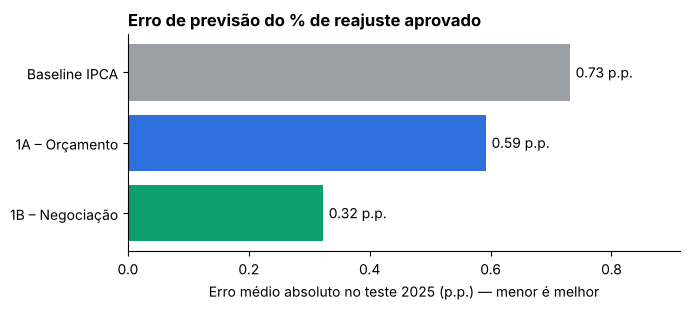

In [9]:
COR = {"base": "#9AA0A6", "A": "#2F6FDE", "B": "#0E9F6E", "real": "#1F2328", "alerta": "#D9480F"}
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

fig, ax = plt.subplots(figsize=(7, 3.2))
nomes = ["Baseline IPCA", "1A – Orçamento", "1B – Negociação"]
vals = resultado["MAE (p.p.)"].values
bars = ax.barh(nomes[::-1], vals[::-1], color=[COR["B"], COR["A"], COR["base"]])
for b_, v in zip(bars, vals[::-1]):
    ax.text(v + 0.01, b_.get_y() + b_.get_height() / 2, f"{v:.2f} p.p.", va="center")
ax.set_xlabel("Erro médio absoluto no teste 2025 (p.p.) — menor é melhor")
ax.set_title("Erro de previsão do % de reajuste aprovado", loc="left", fontweight="bold")
ax.set_xlim(0, vals.max() * 1.25)
plt.tight_layout(); plt.savefig(REP / "figures" / "fig_mae_modelos.png", dpi=160); plt.show()

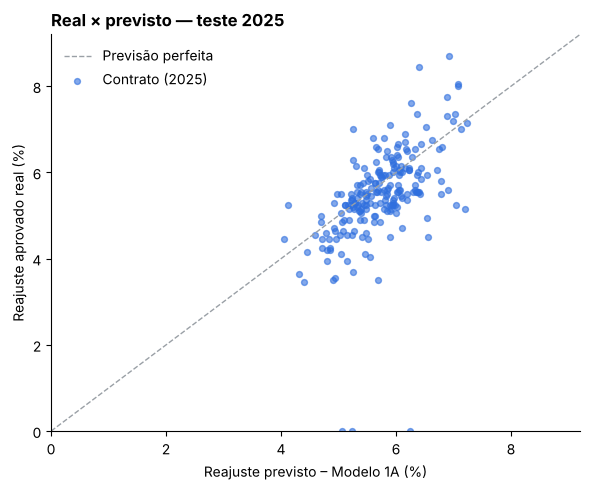

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))
lim = (0, max(t["reajuste_aprovado_pct"].max(), t["prev_A"].max()) + 0.5)
ax.plot(lim, lim, color=COR["base"], lw=1, ls="--", label="Previsão perfeita")
ax.scatter(t["prev_A"], t["reajuste_aprovado_pct"], s=18, alpha=0.6, color=COR["A"], label="Contrato (2025)")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Reajuste previsto – Modelo 1A (%)"); ax.set_ylabel("Reajuste aprovado real (%)")
ax.set_title("Real × previsto — teste 2025", loc="left", fontweight="bold")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.savefig(REP / "figures" / "fig_real_vs_previsto.png", dpi=160); plt.show()

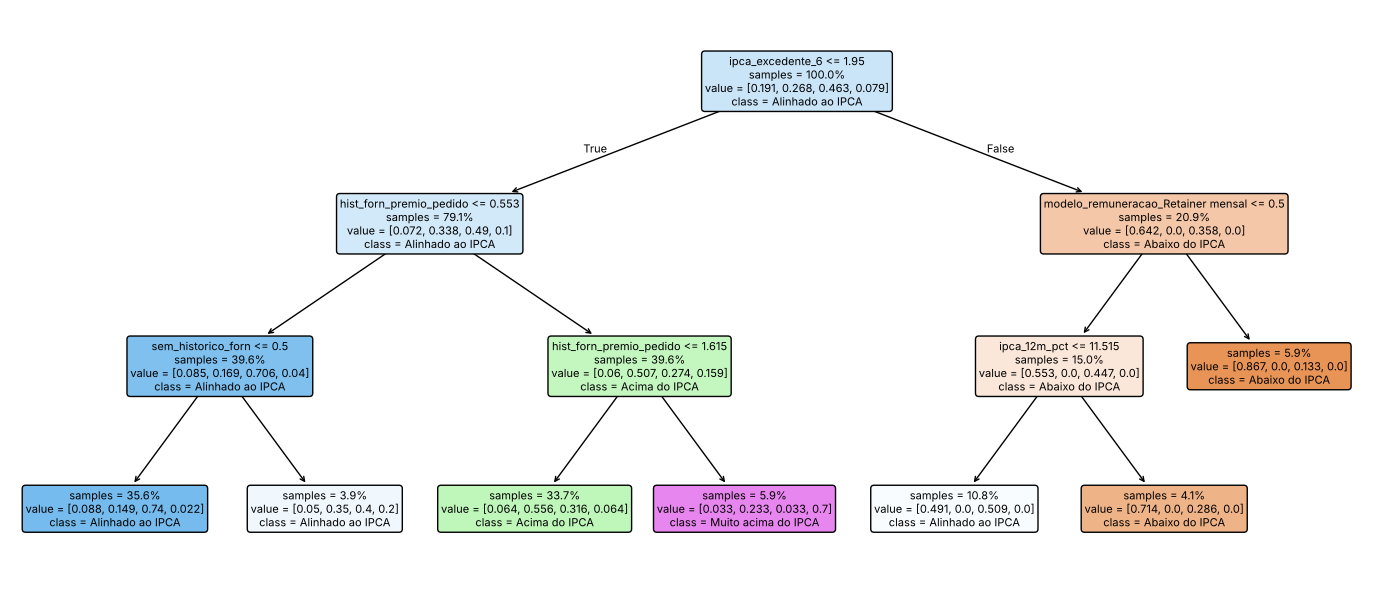

In [11]:
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(arv, feature_names=list(XA_all.columns), class_names=list(arv.classes_), filled=True,
          impurity=False, proportion=True, rounded=True, fontsize=8, ax=ax)
plt.tight_layout(); plt.savefig(REP / "figures" / "fig_arvore.png", dpi=160); plt.show()

## 6. Tabela real × previsto (2025)

In [12]:
COLS_SAIDA = ["id_evento", "id_contrato", "fornecedor_id", "categoria", "data_base_reajuste", "valor_anual_antes",
              "ipca_12m_pct", "prev_A", "faixa_A_min", "faixa_A_max", "reajuste_solicitado_pct", "prev_B",
              "reajuste_aprovado_pct", "faixa_delta_ipca", "prev_faixa", "impacto_prev_A_R$", "impacto_real_R$",
              "oportunidade_B"]
saida = t[COLS_SAIDA].assign(data_base_reajuste=t["data_base_reajuste"].dt.date).rename(columns={
    "prev_A": "previsto_A_pct", "faixa_A_min": "faixa_prev_min_pct", "faixa_A_max": "faixa_prev_max_pct",
    "prev_B": "previsto_B_pct", "reajuste_aprovado_pct": "real_aprovado_pct", "faixa_delta_ipca": "faixa_real",
    "prev_faixa": "faixa_prevista", "impacto_prev_A_R$": "impacto_previsto_R$", "impacto_real_R$": "impacto_real_R$",
    "oportunidade_B": "sinal_oportunidade_negociacao"})
saida["erro_A_pp"] = saida["real_aprovado_pct"] - saida["previsto_A_pct"]
saida["dentro_da_faixa"] = saida["real_aprovado_pct"].between(saida["faixa_prev_min_pct"], saida["faixa_prev_max_pct"]).astype(int)
saida.round(2).to_csv(REP / "real_vs_previsto_2025.csv", sep=";", decimal=",", index=False, encoding="utf-8-sig")
saida.head(10).round(2)

,id_evento,id_contrato,fornecedor_id,categoria,data_base_reajuste,valor_anual_antes,ipca_12m_pct,previsto_A_pct,faixa_prev_min_pct,faixa_prev_max_pct,reajuste_solicitado_pct,previsto_B_pct,real_aprovado_pct,faixa_real,faixa_prevista,impacto_previsto_R$,impacto_real_R$,sinal_oportunidade_negociacao,erro_A_pp,dentro_da_faixa
508,EVT0552,CTR0019,FORN_015,Consultoria Tributária/Contábil,2025-01-01,"503,293.90",4.83,5.24,4.46,6.29,5.55,5.06,5.35,Acima do IPCA,Acima do IPCA,"26,377.87","26,926.22",0,0.11,1
509,EVT0554,CTR0044,FORN_044,Consultoria Tributária/Contábil,2025-01-01,"398,804.21",4.83,5.12,4.33,6.16,7.05,5.87,5.25,Alinhado ao IPCA,Alinhado ao IPCA,"20,415.34","20,937.22",1,0.13,1
510,EVT0555,CTR0073,FORN_019,Consultoria de Tecnologia,2025-01-01,"1,535,820.11",4.83,5.10,4.32,6.15,5.65,5.03,5.25,Alinhado ao IPCA,Alinhado ao IPCA,"78,390.82","80,630.56",0,0.15,1
511,EVT0557,CTR0134,FORN_033,Consultoria de Gestão,2025-01-01,"1,723,504.93",4.83,5.62,4.83,6.66,4.85,4.85,4.85,Alinhado ao IPCA,Alinhado ao IPCA,"96,873.38","83,589.99",0,-0.77,1
512,EVT0558,CTR0156,FORN_070,Auditoria,2025-01-01,"1,744,386.33",4.83,5.25,4.46,6.29,4.85,4.85,3.70,Abaixo do IPCA,Alinhado ao IPCA,"91,581.49","64,542.29",0,-1.55,0
513,EVT0559,CTR0171,FORN_058,Consultoria de Gestão,2025-01-01,"1,489,855.05",4.83,5.24,4.46,6.29,5.00,4.93,0.00,Abaixo do IPCA,Acima do IPCA,"78,114.42",0.00,0,-5.24,0
514,EVT0560,CTR0191,FORN_022,Consultoria de Tecnologia,2025-01-01,"3,404,877.41",4.83,6.04,5.25,7.08,6.25,5.80,5.70,Acima do IPCA,Muito acima do IPCA,"205,569.72","194,078.01",0,-0.34,1
515,EVT0562,CTR0253,FORN_051,Consultoria de Gestão,2025-01-01,"1,802,320.78",4.83,4.69,3.90,5.73,4.85,4.59,4.85,Alinhado ao IPCA,Alinhado ao IPCA,"84,541.93","87,412.56",0,0.16,1
516,EVT0563,CTR0260,FORN_040,Auditoria,2025-01-01,"1,242,065.42",4.83,6.16,5.38,7.21,7.25,6.53,6.70,Muito acima do IPCA,Acima do IPCA,"76,559.00","83,218.38",1,0.54,1
517,EVT0564,CTR0277,FORN_048,Consultoria de Tecnologia,2025-01-01,"1,309,968.69",4.83,4.85,4.06,5.89,4.85,4.80,4.20,Abaixo do IPCA,Alinhado ao IPCA,"63,477.73","55,018.68",0,-0.65,1


## 7. Simulação de uso — 2026
Modelo retreinado com 2022–2025 e aplicado aos eventos de 2026, como seria usado na prática.

In [13]:
tr2 = df["ano"] <= 2025
mA2, loA2, hiA2 = ajustar_regressao(XA_all, y_all, tr2)
mB2, loB2, hiB2 = ajustar_regressao(XB_all, y_all, tr2)
s = df[sim].copy()
s["prev_A"] = mA2.predict(XA_all[sim]).clip(0)
s["min"], s["max"] = (s["prev_A"] + loA2).clip(0), s["prev_A"] + hiA2
print(f"MAE 2026 — baseline: {mean_absolute_error(s.reajuste_aprovado_pct, s.ipca_12m_pct):.2f} p.p. | "
      f"Modelo 1A: {mean_absolute_error(s.reajuste_aprovado_pct, s.prev_A):.2f} p.p.")

# exemplo de saída: contrato com solicitação acima da faixa
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
br = lambda v, d=1: f"{v:,.{d}f}".replace(",", "#").replace(".", ",").replace("#", ".")
ex = s[s["reajuste_solicitado_pct"] > s["max"]].sort_values("valor_anual_antes", ascending=False).iloc[0]
print(f"""PARA A ÁREA REQUISITANTE (antes da solicitação)
  Contrato: {ex.id_contrato} | {ex.categoria}
  Valor atual: R$ {br(ex.valor_anual_antes/1e6, 2)} mi | Data-base: {MESES[ex.data_base_reajuste.month-1]}/{ex.data_base_reajuste.year}
  IPCA utilizado: {br(ex.ipca_12m_pct, 2)}%
  Reajuste estimado: {br(ex['min'])}% a {br(ex['max'])}% (ponto: {br(ex.prev_A)}%)
  Impacto orçamentário estimado: R$ {br(ex.valor_anual_antes*ex['min']/1e5, 0)} mil a R$ {br(ex.valor_anual_antes*ex['max']/1e5, 0)} mil

PARA COMPRAS (após a solicitação)
  Solicitação: {br(ex.reajuste_solicitado_pct, 2)}% | IPCA: {br(ex.ipca_12m_pct, 2)}%
  Faixa esperada pelo modelo: {br(ex['min'])}% a {br(ex['max'])}%
  Prêmio solicitado vs. IPCA: +{br(ex.reajuste_solicitado_pct-ex.ipca_12m_pct, 2)} p.p.
  Indicação: OPORTUNIDADE DE NEGOCIAÇÃO (solicitação acima da faixa esperada)
  [Real ocorrido após negociação: {br(ex.reajuste_aprovado_pct, 2)}%]""")

MAE 2026 — baseline: 0.64 p.p. | Modelo 1A: 0.52 p.p.
PARA A ÁREA REQUISITANTE (antes da solicitação)
  Contrato: CTR0067 | Consultoria de Tecnologia
  Valor atual: R$ 9,52 mi | Data-base: ago/2026
  IPCA utilizado: 4,44%
  Reajuste estimado: 4,3% a 6,1% (ponto: 5,1%)
  Impacto orçamentário estimado: R$ 414 mil a R$ 581 mil

PARA COMPRAS (após a solicitação)
  Solicitação: 6,25% | IPCA: 4,44%
  Faixa esperada pelo modelo: 4,3% a 6,1%
  Prêmio solicitado vs. IPCA: +1,81 p.p.
  Indicação: OPORTUNIDADE DE NEGOCIAÇÃO (solicitação acima da faixa esperada)
  [Real ocorrido após negociação: 4,45%]
